# Quality per Joule: Analysis of the Results

This notebook reproduces every number, table, and figure of the paper from the run records in `results/`.
Run it from the repository root. It needs only `pandas`, `scipy`, and `matplotlib` (no GPU).
DDPM samples with DDIM-100 throughout: in the periodic FID checks, the final FID, and the inference benchmark.

# 1. Setup and Utilities

Imports, the result groups, one table with a row per run, and the helpers used by every later section.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kendalltau, pearsonr

from evaluate import analysis as A  # the repository's plotting style, model names, and colors

%matplotlib inline
A.save = lambda fig, path: fig.tight_layout()  # show the repository's figures inline instead of writing files
pd.set_option("display.max_colwidth", None)

## 1.1 Loading All Runs into One Table

Four result groups: two training budgets (`fixed`, `target`) measured with two tools (`native`, `codegreen`).
In every group, DDPM's final sampling uses DDIM-100.

In [2]:
GROUPS = {("fixed", "native"): "fixed_budget_ddim100__native",
          ("fixed", "codegreen"): "fixed_budget_ddim100_final__codegreen",
          ("target", "native"): "target_quality_fid50_ddim100_final__native",
          ("target", "codegreen"): "target_quality_fid50_ddim100_final__codegreen"}
RAW = {key: A.load_runs(Path("results") / name) for key, name in GROUPS.items()}
SUMMARY = {key: A.summarize([A.run_row(r) for r in group]) for key, group in RAW.items()}  # input of the repository's plots
assert all(r["quality"]["final_sampler"] == "ddim_100" for g in RAW.values() for r in g if r["model"] == "ddpm")

flatten = lambda run, criterion, tool: {
    "criterion": criterion, "tool": tool, **A.run_row(run),  # per-image FLOPs and inference energy use the final sampler
    "train_s": run["energy"]["train"]["duration_s"], "sampling_j": run["energy"]["final_sampling"]["total_j"],
    "idle_w": run["idle_power_w"]["total"]}

runs = pd.DataFrame([flatten(run, *key) for key, group in RAW.items() for run in group])
runs["energy_to_target_j"] = pd.to_numeric(runs.energy_to_target_j, errors="coerce")
runs[["qpj_train", "qpj_train_eval", "qpj_train_inference"]] *= 1e7  # QpJ in units of 1e-7, as in the paper
runs = runs.assign(power_w=runs.train_total_j / runs.train_s,                          # average training power
                   step_j=runs.train_total_j / runs.steps,                             # energy per training step
                   train_flops=runs.steps * runs.flops_train_step,
                   net_cut=1 - runs.train_net_total_j / runs.train_total_j)            # share removed by the idle baseline
runs["pj_per_flop"] = 1e12 * runs.train_total_j / runs.train_flops

native = runs[runs.tool == "native"]  # the paper reports Native measurements
fixed, target = (native[native.criterion == c] for c in ("fixed", "target"))

## 1.2 Helper Functions

In [3]:
def by_model(df):
    """Per-model means over seeds, in the paper's model order."""
    return df.groupby("model", sort=False).mean(numeric_only=True)


def table(df, columns):
    """Paper-style table: one row per model, one 'mean ± std' cell per column = (field, scale, digits)."""
    stats = df.groupby("model", sort=False)
    cells = {name: [f"{m * scale:,.{digits}f} ± {sd * scale:,.{digits}f}" for m, sd in zip(stats[field].mean(), stats[field].std())]
             for name, (field, scale, digits) in columns.items()}
    return pd.DataFrame(cells, index=[A.NAMES[m] for m in df.model.unique()])


def show(numbers, digits=1):
    """Display labelled numbers as a small table."""
    values = [f"{v:,.{digits}f}" if isinstance(v, float) else f"{v:,}" if isinstance(v, int) else v for v in numbers.values()]
    return pd.DataFrame({"value": values}, index=list(numbers))


def ranking(df, field):
    """Models ordered from the highest to the lowest mean of a field."""
    return " > ".join(A.NAMES[m] for m in by_model(df)[field].sort_values(ascending=False).index)


span = lambda s, scale=1, unit="", digits=0: f"{s.min() * scale:,.{digits}f} to {s.max() * scale:,.{digits}f}{unit}"
m, t = by_model(fixed), by_model(target)  # per-model means under each budget
E = m.train_total_j

## 1.3 Completeness Check

Every group must hold 5 models × 3 seeds, all finished.

In [4]:
status = runs.groupby(["criterion", "tool"]).agg(runs=("seed", "size"), models=("model", "nunique"),
                                                 statuses=("status", lambda s: ", ".join(sorted(set(s)))))
assert (status.runs == 15).all() and (status.models == 5).all(), "expected 5 models x 3 seeds in every group"
status

runs  models        statuses
criterion tool                                   
fixed     codegreen    15       5       completed
          native       15       5       completed
target    codegreen    15       5  target_reached
          native       15       5  target_reached

# 2. Measurement Consistency: Native versus CodeGreen

Checks whether the conclusions depend on the measurement tool (Section "Measurement Consistency" of the paper).

## 2.1 Correlation between the Readings of the Two Tools

Each energy measurement of a Native run (training, periodic FID checks, final sampling, inference per 1,000 images)
is paired with the same measurement of the CodeGreen run with the same model, seed, and training budget.

In [5]:
PHASES = ["train_total_j", "eval_total_j", "sampling_j", "inference_j_per_1k"]
pairs = (runs.melt(["criterion", "model", "seed", "tool"], PHASES, "phase", "joules")
             .pivot(index=["criterion", "model", "seed", "phase"], columns="tool", values="joules")
             .query("native > 0"))  # the fixed budget has no periodic checks
pearson, kendall = pearsonr(pairs.native, pairs.codegreen), kendalltau(pairs.native, pairs.codegreen)
show({"Paired measurements": len(pairs), "Pearson r": float(pearson.statistic),
      "Kendall tau": float(kendall.statistic), "Kendall p-value": f"{kendall.pvalue:.1e}"}, digits=4)

,value
Paired measurements,105
Pearson r,1.0000
Kendall tau,0.9125
Kendall p-value,2.7e-43


## 2.2 Absolute Difference: Energy per Step, Idle Baseline, and Net Energy

Energy is compared per training step, because under the quality target the two tools' runs stop at different epochs.

In [6]:
gap = runs.pivot_table(index=["criterion", "model"], columns="tool", values="step_j", sort=False)
gap["CodeGreen above Native (%)"] = 100 * (gap.codegreen / gap.native - 1)
display(gap.rename(index=A.NAMES).round(3))
tools = runs.groupby("tool")
show({"CodeGreen above Native, energy per training step": span(gap["CodeGreen above Native (%)"], unit=" %"),
      **{f"Idle baseline, {tool}": span(g.idle_w, unit=" W") for tool, g in tools},
      **{f"Training energy removed by the idle baseline, {tool}": span(g.net_cut, 100, " %") for tool, g in tools}})

tool               native  codegreen  CodeGreen above Native (%)
criterion model                                                 
fixed     AE        0.665      0.792                      19.155
          VAE       0.686      0.836                      21.795
          DCGAN     0.979      1.173                      19.784
          WGAN-GP   6.288      7.472                      18.830
          DDPM     20.578     25.475                      23.794
target    AE        0.666      0.787                      18.172
          VAE       0.687      0.832                      20.960
          DCGAN     0.958      1.151                      20.157
          WGAN-GP   6.304      7.454                      18.246
          DDPM     20.478     25.204                      23.080

,value
"CodeGreen above Native, energy per training step",18 to 24 %
"Idle baseline, codegreen",75 to 103 W
"Idle baseline, native",22 to 36 W
"Training energy removed by the idle baseline, codegreen",36 to 55 %
"Training energy removed by the idle baseline, native",13 to 22 %


## 2.3 Do Both Tools Rank the Models Identically?

In [7]:
METRICS = {"train_total_j": "Training energy", "qpj_train": "QpJ (T)", "qpj_train_eval": "QpJ (T+E)", "qpj_train_inference": "QpJ (T+S)"}
agreement = pd.DataFrame([{"budget": c, "metric": name, **{tool: ranking(g[g.tool == tool], field) for tool in ("native", "codegreen")}}
                          for c, g in runs.groupby("criterion") for field, name in METRICS.items()]).set_index(["budget", "metric"])
agreement["identical"] = agreement.native == agreement.codegreen
agreement

native  \
budget metric                                               
fixed  Training energy  DDPM > WGAN-GP > DCGAN > VAE > AE   
       QpJ (T)          DCGAN > WGAN-GP > AE > VAE > DDPM   
       QpJ (T+E)        DCGAN > WGAN-GP > AE > VAE > DDPM   
       QpJ (T+S)        DCGAN > WGAN-GP > AE > VAE > DDPM   
target Training energy  DDPM > VAE > WGAN-GP > AE > DCGAN   
       QpJ (T)          DCGAN > AE > WGAN-GP > DDPM > VAE   
       QpJ (T+E)        DCGAN > AE > WGAN-GP > DDPM > VAE   
       QpJ (T+S)        DCGAN > AE > WGAN-GP > VAE > DDPM   

                                                codegreen  identical  
budget metric                                                         
fixed  Training energy  DDPM > WGAN-GP > DCGAN > VAE > AE       True  
       QpJ (T)          DCGAN > WGAN-GP > AE > VAE > DDPM       True  
       QpJ (T+E)        DCGAN > WGAN-GP > AE > VAE > DDPM       True  
       QpJ (T+S)        DCGAN > WGAN-GP > AE > VAE > DDPM       True  
target Training energy  DDPM > VAE > WGAN-GP > AE > DCGAN       True  
       QpJ (T)          DCGAN > AE > WGAN-GP > DDPM > VAE       True  
       QpJ (T+E)        DCGAN > AE > WGAN-GP > DDPM > VAE       True  
       QpJ (T+S)        DCGAN > AE > WGAN-GP > VAE > DDPM       True

# 3. RQ1: Energy Consumption per Model

Native measurements under the fixed budget (30 epochs).

## 3.1 Model Size and Computational Cost

Parameters and FLOPs per training step and per generated image (DDPM: DDIM-100).

In [8]:
pd.DataFrame({"Params (M)": m.params / 1e6, "GFLOPs per training step": m.flops_train_step / 1e9,
              "GFLOPs per image": m.flops_image / 1e9}).rename(index=A.NAMES).round(3)

,Params (M),GFLOPs per training step,GFLOPs per image
model,,,
AE,2.367,6.895,0.036
VAE,2.892,6.996,0.036
DCGAN,1.847,13.458,0.036
WGAN-GP,1.847,79.555,0.036
DDPM,35.746,1194.366,1244.371


## 3.2 Training and Inference Energy under the Fixed Budget

Training energy (scope T) over 30 epochs; inference energy per 1,000 images.

In [9]:
table(fixed, {"Training (kJ)": ("train_total_j", 1e-3, 1), "Training time (min)": ("train_s", 1 / 60, 1),
              "Inference (J per 1,000 images)": ("inference_j_per_1k", 1, 2)})

,Training (kJ),Training time (min),"Inference (J per 1,000 images)"
AE,101.5 ± 2.4,10.1 ± 0.3,2.30 ± 0.01
VAE,104.7 ± 0.5,10.7 ± 0.1,2.29 ± 0.01
DCGAN,149.4 ± 2.3,14.7 ± 0.3,2.27 ± 0.03
WGAN-GP,191.9 ± 3.1,19.6 ± 0.3,2.25 ± 0.08
DDPM,"3,140.2 ± 10.5",315.0 ± 0.1,"19,454.49 ± 19.28"


## 3.3 Training Energy: Network and Training Method

In [10]:
show({"Lowest training energy, AE (kJ)": E.ae / 1e3, "Highest training energy, DDPM (MJ)": E.ddpm / 1e6,
      "DDPM / AE": E.ddpm / E.ae, "DCGAN / AE": E.dcgan / E.ae, "WGAN-GP / DCGAN": E.wgan_gp / E.dcgan,
      "WGAN-GP / AE (largest shared-backbone spread)": E.wgan_gp / E.ae}, digits=2)

,value
"Lowest training energy, AE (kJ)",101.48
"Highest training energy, DDPM (MJ)",3.14
DDPM / AE,30.94
DCGAN / AE,1.47
WGAN-GP / DCGAN,1.28
WGAN-GP / AE (largest shared-backbone spread),1.89


## 3.4 Where the Training Energy Goes

,GPU (%),CPU (%),RAM (%)
model,,,
AE,60.41,39.19,0.41
VAE,59.45,40.13,0.42
DCGAN,60.75,38.85,0.40
WGAN-GP,58.82,40.74,0.44
DDPM,81.17,18.44,0.39


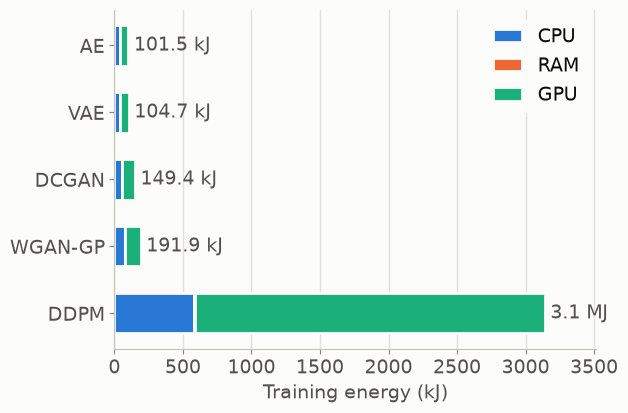

In [11]:
shares = 100 * m[["train_gpu_j", "train_cpu_j", "train_ram_j"]].div(E, axis=0)
shares.columns = ["GPU (%)", "CPU (%)", "RAM (%)"]
display(shares.rename(index=A.NAMES).round(2))
A.plot_energy_breakdown(SUMMARY["fixed", "native"], None)

## 3.5 Inference Energy

In [12]:
inference = m.inference_j_per_1k
show({"Single-pass models (J per 1,000 images)": span(inference.drop("ddpm"), digits=2),
      "DDPM (J per 1,000 images)": inference.ddpm, "DDPM / AE": inference.ddpm / inference.ae}, digits=0)

,value
"Single-pass models (J per 1,000 images)",2.25 to 2.30
"DDPM (J per 1,000 images)","19,454"
DDPM / AE,"8,475"


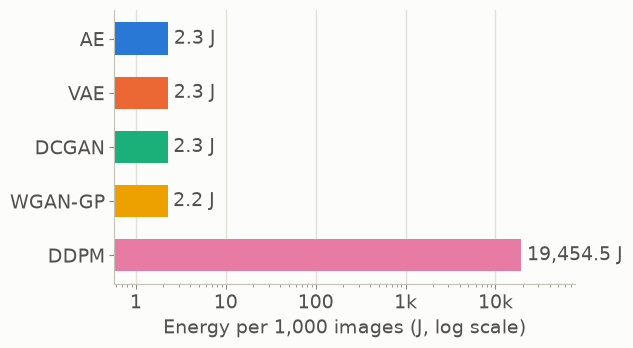

In [13]:
A.bar_chart([A.NAMES[k] for k in m.index], list(inference), [A.COLORS[k] for k in m.index],
            "Energy per 1,000 images (J, log scale)", None, lambda v: f"{v:,.1f} J")

### Inference Benchmark Settings

Each model samples in fixed batches until it has generated at least `inference_images` images
and sampled for at least `inference_min_s` seconds (Section III-E). DDPM row: DDIM-100.

In [14]:
import yaml
group = Path("results") / GROUPS["fixed", "native"]
ev = yaml.safe_load(next(group.glob("runs/*/seed*/config.yaml")).read_text())["evaluation"]
bench = pd.concat([pd.read_csv(p).assign(model=p.parts[-3]) for p in group.glob("runs/*/seed*/inference.csv")])
bench = bench[bench.sampler.isin(["direct", "ddim_100"])].groupby("model").agg(
    batch=("batch_size", "first"), images_min=("n_images", "min"), images_max=("n_images", "max"), seconds=("duration_s", "mean"))
display(show({"Batch size": ev["batch_size"], "Minimum images": ev["inference_images"], "Minimum duration (s)": ev["inference_min_s"]}))
display(bench.reindex(m.index).rename(index=A.NAMES).round(1))

,value
Batch size,250
Minimum images,"1,000"
Minimum duration (s),30


,batch,images_min,images_max,seconds
model,,,,
AE,250,2163000,2166250,30.2
VAE,250,2175000,2176500,30.2
DCGAN,250,2176750,2262000,30.2
WGAN-GP,250,2176500,2298000,30.2
DDPM,250,1000,1000,111.1


# 4. RQ2: Proxies for Energy

Training energy and three proxies relative to the AE under the fixed budget. A proxy that tracks energy matches the energy
column; "Same order as energy" tells whether it at least ranks the models as energy does.

## 4.1 Parameters, FLOPs, and Time versus Energy

In [15]:
relative = lambda s: s / s.ae
proxies = pd.DataFrame({"Energy": relative(E), "Params": relative(m.params), "FLOPs": relative(m.train_flops), "Time": relative(m.train_s)})
order = lambda s: list(s.sort_values().index)
display(proxies.rename(index=A.NAMES).round(2))
pd.Series({p: order(proxies[p]) == order(proxies.Energy) for p in proxies.columns[1:]}, name="Same order as energy").to_frame()

,Energy,Params,FLOPs,Time
model,,,,
AE,1.00,1.00,1.00,1.00
VAE,1.03,1.22,1.01,1.06
DCGAN,1.47,0.78,1.95,1.45
WGAN-GP,1.89,0.78,2.31,1.93
DDPM,30.94,15.10,173.21,31.10


,Same order as energy
Params,False
FLOPs,True
Time,True


## 4.2 How Much FLOPs Overstate Energy

In [16]:
show({"DDPM / AE, training FLOPs": proxies.FLOPs.ddpm, "DDPM / AE, training energy": proxies.Energy.ddpm,
      "FLOPs overstate DDPM's training energy by (×)": proxies.FLOPs.ddpm / proxies.Energy.ddpm,
      "DDPM / AE, FLOPs per image": m.flops_image.ddpm / m.flops_image.ae,
      "DDPM / AE, inference energy per image": inference.ddpm / inference.ae,
      "FLOPs overstate DDPM's inference energy by (×)": (m.flops_image.ddpm / m.flops_image.ae) / (inference.ddpm / inference.ae)})

,value
"DDPM / AE, training FLOPs",173.2
"DDPM / AE, training energy",30.9
FLOPs overstate DDPM's training energy by (×),5.6
"DDPM / AE, FLOPs per image","34,366.7"
"DDPM / AE, inference energy per image","8,474.8"
FLOPs overstate DDPM's inference energy by (×),4.1


## 4.3 GPU Utilization and Power by Component

Achieved throughput = training FLOPs per second, relative to the RTX 2080 SUPER's nominal FP32 peak of 11.15 TFLOPS.

In [17]:
PEAK_FLOPS = 11.15e12
utilization = pd.DataFrame({"Achieved TFLOPS": m.train_flops / m.train_s / 1e12,
                            "Share of FP32 peak (%)": 100 * m.train_flops / m.train_s / PEAK_FLOPS,
                            "pJ per FLOP": m.pj_per_flop, "Total power (W)": m.power_w,
                            "GPU power (W)": m.train_gpu_j / m.train_s, "CPU power (W)": m.train_cpu_j / m.train_s})
display(utilization.rename(index=A.NAMES).round(1))
show({"Average training power across models": span(m.power_w, unit=" W"),
      "Largest difference in training power (%)": 100 * (m.power_w.max() / m.power_w.min() - 1),
      "Largest gap between time and energy ratios (%)": 100 * (proxies.Time / proxies.Energy - 1).abs().max()})

,Achieved TFLOPS,Share of FP32 peak (%),pJ per FLOP,Total power (W),GPU power (W),CPU power (W)
model,,,,,,
AE,1.7,15.5,96.4,167.0,100.9,65.4
VAE,1.7,14.9,98.1,162.9,96.8,65.4
DCGAN,2.3,20.9,72.7,169.6,103.0,65.9
WGAN-GP,2.1,18.5,79.0,163.3,96.0,66.5
DDPM,9.6,86.5,17.2,166.1,134.9,30.6


,value
Average training power across models,163 to 170 W
Largest difference in training power (%),4.1
Largest gap between time and energy ratios (%),2.5


# 5. RQ3: Quality per Joule

QpJ = 1 / (FID × energy), in units of 10⁻⁷ (higher is better), for three energy scopes:
T = training, T+E = training and periodic FID checks, T+S = training and final sampling of 10,000 images.

## 5.1 FID, Energy-to-Target, and QpJ under Both Training Budgets

In [18]:
QPJ = {"QpJ T": ("qpj_train", 1, 2), "QpJ T+E": ("qpj_train_eval", 1, 2), "QpJ T+S": ("qpj_train_inference", 1, 2)}
pd.concat({"Fixed budget (30 epochs)": table(fixed, {"FID": ("final_fid", 1, 2), "QpJ T": QPJ["QpJ T"], "QpJ T+S": QPJ["QpJ T+S"]}),
           "Quality target (FID ≤ 50)": table(target, {"Epochs": ("epochs", 1, 1), "Energy-to-target (kJ)": ("energy_to_target_j", 1e-3, 1),
                                                       "FID": ("final_fid", 1, 2), **QPJ})}, axis=1)

Fixed budget (30 epochs)                            \
                             FID        QpJ T      QpJ T+S   
AE                  42.81 ± 0.54  2.30 ± 0.08  2.30 ± 0.08   
VAE                 50.44 ± 0.16  1.89 ± 0.00  1.89 ± 0.00   
DCGAN               11.43 ± 0.31  5.86 ± 0.07  5.86 ± 0.07   
WGAN-GP             20.76 ± 0.34  2.51 ± 0.03  2.51 ± 0.03   
DDPM                 5.88 ± 0.29  0.54 ± 0.03  0.51 ± 0.03   

        Quality target (FID ≤ 50)                                      \
                           Epochs Energy-to-target (kJ)           FID   
AE                      6.7 ± 1.5            22.6 ± 5.2  48.26 ± 1.09   
VAE                    37.0 ± 8.0          129.4 ± 28.0  48.89 ± 0.61   
DCGAN                   2.0 ± 0.0             9.7 ± 0.1  37.69 ± 2.09   
WGAN-GP                 7.3 ± 0.6            47.0 ± 3.9  45.32 ± 0.63   
DDPM                    2.0 ± 0.0           208.3 ± 2.6  16.32 ± 0.95   

                                                   
                QpJ T       QpJ T+E       QpJ T+S  
AE        9.53 ± 2.32   6.26 ± 1.50   9.52 ± 2.32  
VAE       1.63 ± 0.37   1.09 ± 0.24   1.63 ± 0.37  
DCGAN    27.28 ± 1.52  20.15 ± 1.16  27.21 ± 1.53  
WGAN-GP   4.71 ± 0.43   3.71 ± 0.34   4.71 ± 0.43  
DDPM      2.95 ± 0.14   1.50 ± 0.07   1.53 ± 0.07

## 5.2 Fixed Budget: Trade-off between DCGAN and DDPM, and Dominated Models

A model is dominated when another model consumes less training energy and achieves a lower FID.

In [19]:
show({"DCGAN / DDPM, FID (×)": m.final_fid.dcgan / m.final_fid.ddpm, "DDPM / DCGAN, training energy (×)": E.ddpm / E.dcgan,
      "DCGAN / DDPM, QpJ T (×)": m.qpj_train.dcgan / m.qpj_train.ddpm,
      "DCGAN / DDPM, QpJ T+S (×)": m.qpj_train_inference.dcgan / m.qpj_train_inference.ddpm,
      "DDPM final sampling (kJ)": m.sampling_j.ddpm / 1e3, "DDPM final sampling / training energy (%)": 100 * m.sampling_j.ddpm / E.ddpm,
      "Final sampling, single-pass models (J)": span(m.sampling_j.drop("ddpm"))}, digits=2)

,value
"DCGAN / DDPM, FID (×)",1.94
"DDPM / DCGAN, training energy (×)",21.02
"DCGAN / DDPM, QpJ T (×)",10.81
"DCGAN / DDPM, QpJ T+S (×)",11.47
DDPM final sampling (kJ),193.93
DDPM final sampling / training energy (%),6.18
"Final sampling, single-pass models (J)",23 to 33


,Dominated by (fixed budget),Dominated by (quality target)
AE,–,DCGAN
VAE,AE,"AE, DCGAN, WGAN-GP"
DCGAN,–,–
WGAN-GP,DCGAN,DCGAN
DDPM,–,–


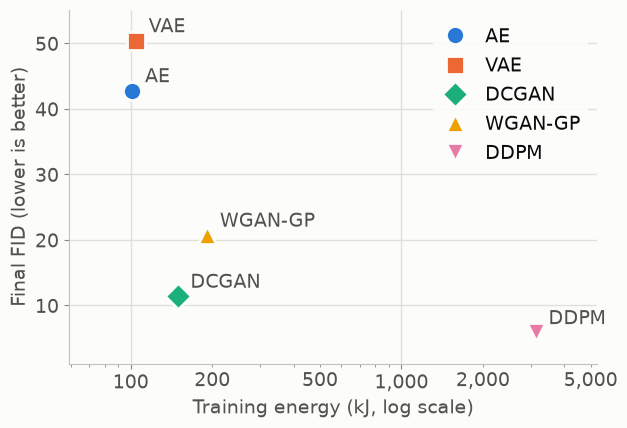

In [20]:
def dominated(df):
    """For each model, the models that are both cheaper to train and better in FID."""
    d = by_model(df)
    better = lambda a: [A.NAMES[b] for b in d.index if d.train_total_j[b] < d.train_total_j[a] and d.final_fid[b] < d.final_fid[a]]
    return pd.Series({A.NAMES[a]: ", ".join(better(a)) or "–" for a in d.index})


display(pd.DataFrame({"Dominated by (fixed budget)": dominated(fixed), "Dominated by (quality target)": dominated(target)}))
A.plot_fid_vs_energy(SUMMARY["fixed", "native"], None)

## 5.3 Quality Target: Energy to First Reach FID ≤ 50, and the Cost of Evaluation

In [21]:
pd.DataFrame({"Epochs (min to max)": target.groupby("model", sort=False).epochs.agg(lambda s: span(s)),
              "Energy-to-target (kJ)": t.energy_to_target_j / 1e3, "Energy-to-target (× DCGAN)": t.energy_to_target_j / t.energy_to_target_j.dcgan,
              "Periodic checks (% of training)": 100 * t.eval_total_j / t.train_total_j,
              "Final sampling (kJ)": t.sampling_j / 1e3, "Final sampling (× training)": t.sampling_j / t.train_total_j}).rename(index=A.NAMES).round(2)

,Epochs (min to max),Energy-to-target (kJ),Energy-to-target (× DCGAN),Periodic checks (% of training),Final sampling (kJ),Final sampling (× training)
model,,,,,,
AE,5 to 8,22.59,2.32,52.06,0.02,0.00
VAE,29 to 45,129.39,13.27,49.86,0.02,0.00
DCGAN,2 to 2,9.75,1.00,35.37,0.02,0.00
WGAN-GP,7 to 8,47.05,4.83,27.05,0.02,0.00
DDPM,2 to 2,208.34,21.38,95.88,193.23,0.93


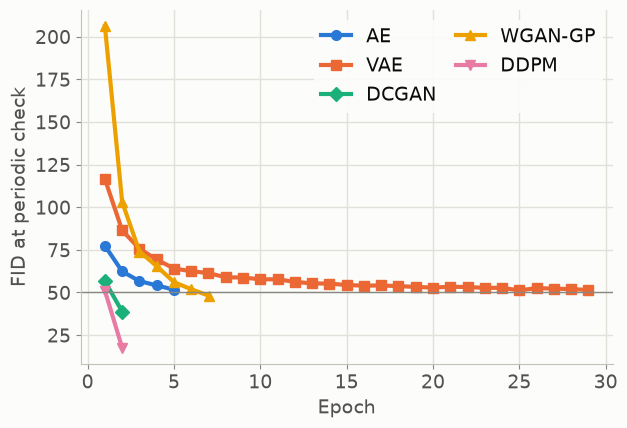

In [22]:
A.plot_lines(A.model_curves(RAW["target", "native"], A.fid_curve), "Epoch", "FID at periodic check", None, hline=50, log=False)

## 5.4 Energy-to-Target with Interpolated Crossing

FID is checked once per epoch, so a model that crosses the target between checks is stopped late. The crossing is estimated by
linear interpolation in cumulative training energy between the last check above the target and the first check at or below it.

In [23]:
def crossing_energy(run, target_fid=50):
    """Training energy at the interpolated FID crossing, using the per-epoch training segments."""
    checks = pd.read_csv(run["dir"] / "fid_history.csv")
    energy = pd.read_csv(run["dir"] / "energy_segments.csv").query("phase == 'train'").total_j.cumsum().to_numpy()[:len(checks)]
    fid = checks.fid.to_numpy()
    i = int(np.argmax(fid <= target_fid))
    return energy[0] if i == 0 else energy[i - 1] + (fid[i - 1] - target_fid) / (fid[i - 1] - fid[i]) * (energy[i] - energy[i - 1])


crossing = pd.DataFrame([{"model": r["model"], "measured": r["quality"]["target_reached_at"]["train_total_j"], "interpolated": crossing_energy(r)}
                         for r in RAW["target", "native"]]).groupby("model", sort=False).mean()
crossing["measured / interpolated"] = crossing.measured / crossing.interpolated
display((crossing[["measured", "interpolated"]] / 1e3).join(crossing["measured / interpolated"]).rename(index=A.NAMES).round(2))
show({"DDPM / DCGAN energy-to-target, measured": crossing.measured.ddpm / crossing.measured.dcgan,
      "DDPM / DCGAN energy-to-target, interpolated": crossing.interpolated.ddpm / crossing.interpolated.dcgan})

,measured,interpolated,measured / interpolated
model,,,
AE,22.59,20.74,1.09
VAE,129.39,128.46,1.01
DCGAN,9.75,6.63,1.47
WGAN-GP,47.05,41.78,1.13
DDPM,208.34,107.19,1.94


,value
"DDPM / DCGAN energy-to-target, measured",21.4
"DDPM / DCGAN energy-to-target, interpolated",16.2


## 5.5 Robustness: Rankings, Training Point, and Quality Weight

### Rankings by Training Budget and Energy Scope

Models ordered from the highest to the lowest QpJ, and DCGAN's QpJ relative to DDPM's in each setting.

In [25]:
SCOPES = {"qpj_train": "QpJ (T)", "qpj_train_eval": "QpJ (T+E)", "qpj_train_inference": "QpJ (T+S)"}
rankings = pd.DataFrame([{"budget": b, "scope": name, "ranking": ranking(df, field), "DCGAN / DDPM": by_model(df)[field].dcgan / by_model(df)[field].ddpm}
                         for b, df in (("Fixed budget", fixed), ("Quality target", target)) for field, name in SCOPES.items()
                         if not (b == "Fixed budget" and field == "qpj_train_eval")]).set_index(["budget", "scope"])
display(rankings.round(1))
show({"Largest DCGAN / DDPM QpJ ratio (×)": rankings["DCGAN / DDPM"].max(),
      "Quality target, VAE QpJ T+S (mean ± std)": f"{target[target.model == 'vae'].qpj_train_inference.mean():.2f} ± {target[target.model == 'vae'].qpj_train_inference.std():.2f}",
      "Quality target, DDPM QpJ T+S (mean ± std)": f"{target[target.model == 'ddpm'].qpj_train_inference.mean():.2f} ± {target[target.model == 'ddpm'].qpj_train_inference.std():.2f}"})

ranking  DCGAN / DDPM
budget         scope                                                     
Fixed budget   QpJ (T)    DCGAN > WGAN-GP > AE > VAE > DDPM          10.8
               QpJ (T+S)  DCGAN > WGAN-GP > AE > VAE > DDPM          11.5
Quality target QpJ (T)    DCGAN > AE > WGAN-GP > DDPM > VAE           9.3
               QpJ (T+E)  DCGAN > AE > WGAN-GP > DDPM > VAE          13.4
               QpJ (T+S)  DCGAN > AE > WGAN-GP > VAE > DDPM          17.8

,value
Largest DCGAN / DDPM QpJ ratio (×),17.8
"Quality target, VAE QpJ T+S (mean ± std)",1.63 ± 0.37
"Quality target, DDPM QpJ T+S (mean ± std)",1.53 ± 0.07


### QpJ Falls as Training Continues

Training-only QpJ at each model's two measured points: where it reached the quality target, and after 30 epochs.
The last column divides the QpJ at the earlier point by the QpJ at the later one (the VAE reaches the target after 30 epochs).

In [26]:
points = pd.DataFrame({"Epochs at quality target": t.epochs, "QpJ at quality target": t.qpj_train, "QpJ after 30 epochs": m.qpj_train})
points["Earlier / later point"] = np.where(t.epochs < 30, t.qpj_train / m.qpj_train, m.qpj_train / t.qpj_train)
points.rename(index=A.NAMES).round(2)

,Epochs at quality target,QpJ at quality target,QpJ after 30 epochs,Earlier / later point
model,,,,
AE,6.67,9.53,2.30,4.14
VAE,37.00,1.63,1.89,1.16
DCGAN,2.00,27.28,5.86,4.66
WGAN-GP,7.33,4.71,2.51,1.88
DDPM,2.00,2.95,0.54,5.44


### Sensitivity to the Weight of Quality

QpJ with a quality weight k: 1 / (FID^k × E). For each setting, the range of k over which DCGAN has the highest QpJ,
and the model that overtakes it at each end (computed from per-model means).

In [27]:
def dcgan_lead(fid, energy):
    """k range where FID_dcgan^k E_dcgan is the lowest: cheaper models set the lower bound, better-FID models the upper."""
    a, c = np.log(fid.dcgan / fid).drop("dcgan"), np.log(energy / energy.dcgan).drop("dcgan")
    lower, upper = (c / a)[a < 0], (c / a)[a > 0]
    return {"k from": max(lower.max(), 0) if len(lower) else 0.0, "overtaken below by": A.NAMES[lower.idxmax()] if len(lower) else "–",
            "k up to": upper.min() if len(upper) else np.inf, "overtaken above by": A.NAMES[upper.idxmin()] if len(upper) else "–"}


SETTINGS = {"Fixed budget, T": (m.final_fid, E), "Fixed budget, T+S": (m.final_fid, E + m.sampling_j),
            "Quality target, T": (t.final_fid, t.train_total_j), "Quality target, T+E": (t.final_fid, t.train_total_j + t.eval_total_j),
            "Quality target, T+S": (t.final_fid, t.train_total_j + t.sampling_j)}
lead = pd.DataFrame({name: dcgan_lead(*values) for name, values in SETTINGS.items()}).T
lead[["k from", "k up to"]] = lead[["k from", "k up to"]].astype(float).round(2)
lead

,k from,overtaken below by,k up to,overtaken above by
"Fixed budget, T",0.29,AE,4.59,DDPM
"Fixed budget, T+S",0.29,AE,4.67,DDPM
"Quality target, T",0.00,AE,3.66,DDPM
"Quality target, T+E",0.00,AE,4.10,DDPM
"Quality target, T+S",0.00,AE,4.44,DDPM


## 5.6 Consistency of the Recorded Training Energy

The per-epoch FID log records cumulative training energy at each check; at the stop it should equal the training energy in the run
record. Runs that differ by more than 1% are listed.

In [28]:
log_energy = pd.DataFrame([{"model": A.NAMES[r["model"]], "seed": r["seed"], "run record (kJ)": r["energy"]["train"]["total_j"] / 1e3,
                            "FID log (kJ)": pd.read_csv(r["dir"] / "fid_history.csv").cum_train_total_j.iloc[-1] / 1e3} for r in RAW["target", "native"]])
log_energy["difference (%)"] = 100 * (log_energy["FID log (kJ)"] / log_energy["run record (kJ)"] - 1)
log_energy[log_energy["difference (%)"].abs() > 1].round(1)

,model,seed,run record (kJ),FID log (kJ),difference (%)
13,DDPM,1337,206.3,235.3,14.0


# 6. Discussion: Numbers behind the Interpretation

A smartphone charge is taken as 0.012 kWh (43.2 kJ), following Luccioni et al. (2024).

In [29]:
PHONE_CHARGE_J = 0.012 * 3.6e6
show({"DCGAN / DDPM, FID under the fixed budget (×)": m.final_fid.dcgan / m.final_fid.ddpm,
      "DCGAN training energy as a fraction of DDPM's": f"1/{E.ddpm / E.dcgan:.0f}",
      "DDPM / DCGAN, inference energy per image (×)": inference.ddpm / inference.dcgan,
      "DCGAN energy-to-target (kJ)": t.energy_to_target_j.dcgan / 1e3,
      "DCGAN energy-to-target / smartphone charge": t.energy_to_target_j.dcgan / PHONE_CHARGE_J,
      "VAE / DCGAN, FID with the same network (×)": m.final_fid.vae / m.final_fid.dcgan, "DCGAN / VAE, training energy (×)": E.dcgan / E.vae,
      "Quality target: AE / DDPM, QpJ T (×)": t.qpj_train.ae / t.qpj_train.ddpm, "Quality target: AE / DDPM, FID (×)": t.final_fid.ae / t.final_fid.ddpm}, digits=2)

,value
"DCGAN / DDPM, FID under the fixed budget (×)",1.94
DCGAN training energy as a fraction of DDPM's,1/21
"DDPM / DCGAN, inference energy per image (×)","8,588.77"
DCGAN energy-to-target (kJ),9.75
DCGAN energy-to-target / smartphone charge,0.23
"VAE / DCGAN, FID with the same network (×)",4.41
"DCGAN / VAE, training energy (×)",1.43
"Quality target: AE / DDPM, QpJ T (×)",3.23
"Quality target: AE / DDPM, FID (×)",2.96
